# Lesson 5 — A reusable backtesting engine

**Separate concerns, account honestly, resolve ambiguity, and prove there is no look-ahead.**

---

In [1]:
# --- environment setup (run me first) -------------------------------------
import sys, os, textwrap, json, tempfile
from pathlib import Path

import numpy as np
import pandas as pd

# The notebooks live in <module>/notebooks; the package lives in <module>/.
BASE = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "intraday_engine").is_dir())
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

DATA = BASE / "data"
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

from intraday_engine import *          # noqa: F401,F403
from intraday_engine.core import Fill  # noqa: F401

print("module root :", BASE)
print("pandas      :", pd.__version__, "| numpy:", np.__version__)
print("data files  :", sorted(p.name for p in DATA.glob("*.csv")))

module root : /home/user/Algorithmic_Trading_with_Python/Event_Driven_Intraday
pandas      : 3.0.6 | numpy: 2.4.6
data files  : ['pattern_sample.csv', 'sample_1min_crypto_3d.csv', 'sample_5min_equity_1m.csv']


## 1. Learning objectives

By the end of this lesson you can:

1. **Separate** the five concerns — data, strategy, execution, portfolio, logging — and explain what each one is allowed to know.
2. **Wire** them into a single bar loop where the order of operations itself prevents look-ahead.
3. **Account** for cash, positions, fees and mark-to-market equity, and reconcile the equity curve against the trade log.
4. **Audit** an engine: mutation tests, determinism tests, rejection review, and a conservative/optimistic intrabar comparison.
5. **Reason** about complexity and memory (batch vs streaming) and choose the right mode for 5,000 bars or 5 million.

## 2. Key concepts and definitions

| Term | Meaning |
|---|---|
| **Separation of concerns** | Each component has one reason to change; a strategy cannot touch cash, the portfolio cannot see the future. |
| **Dependency injection** | Components receive their collaborators (data, logger, portfolio) instead of constructing them. This is what makes them swappable and testable. |
| **Event-driven** | The system advances by processing events (a completed bar) rather than by vectorised formulas over the whole history. |
| **Bar loop** | `for t in range(n_bars): step(t)`. The engine's heartbeat. |
| **Execution engine** | Accepts orders and produces fills under explicit cost and intrabar rules. |
| **Portfolio / account** | The only component allowed to change cash and position; produces equity and trades. |
| **Mark-to-market** | Valuing the open position at the latest close: `equity = cash + position × price`. |
| **Equity curve** | One row per bar: equity, cash, position, realised/unrealised PnL. |
| **Drawdown** | `equity / running_max − 1`; max drawdown is its minimum. |
| **Reconciliation** | Proving that the accounting identities hold (trades ↔ equity ↔ cash). |
| **Anti-look-ahead** | Structural prevention: cursor, order activation delay, next-bar fills, causal indicators. |
| **Intrabar ambiguity** | Unknown path inside a bar; resolved conservatively. |
| **Determinism** | Same inputs + same code ⇒ identical outputs; no clock, no unseeded RNG. |
| **Batch backtest** | Iterate a fixed DataFrame as fast as possible. |
| **Streaming backtest / paper trading** | Feed one bar at a time from a live source; identical strategy code. |
| **Complexity** | Time per bar must be O(1) amortised; total O(n). Avoid O(n²) slices of the whole history. |
| **Walk-forward** | Fit on a window, trade the next window, roll; the minimum honest validation. |

## 3. Step-by-step walkthrough

### 3.1 The five components and their contracts

| Component | Knows about | Must **not** know | Public surface |
|---|---|---|---|
| `DataHandler` | OHLCV, cursor | orders, cash, strategy | `bar(t)`, `window(t,n)`, `window_before`, `set_cursor` |
| `Strategy` | `Context` (history ≤ t), its state, the portfolio *read-only* | fills, future bars, cash mutation | `on_start`, `on_bar`, `on_fill`, `on_reject`, `on_finish` |
| `ExecutionEngine` | orders, bar OHLC, cost model, brackets | strategy internals, PnL | `submit`, `process_bar`, `drain_rejections` |
| `Portfolio` | fills, marks | strategy, future prices | `apply_fill`, `mark`, `equity_curve`, `trades` |
| `EventLogger` | events | everything else | `log`, `to_frame`, `events_of_kind` |

### 3.2 The wiring (and why the order matters)

```
for t in bars:
    data.set_cursor(t)                  # 1. future reads now raise
    ctx = Context(bar=t, history=0..t)  # 2. the strategy's world
    orders = strategy.on_bar(ctx)       # 3. decisions only
    execution.submit(order, bar_t)      #    orders are stamped t
    fills = execution.process_bar(bar)  # 4. exits for old positions, then
                                        #    orders from bars < t, then fresh brackets
    portfolio.mark(close_t)             # 5. one equity row
```

Two structural guarantees fall out of this order:

- an order submitted at `t` is skipped while `bar.index == t` (activation delay),
- a market order can only ever fill at an open, never at the signal bar's close.

### 3.3 Accounting identities (memorise these)

```
equity(t)  = cash(t) + position(t) × close(t)
cash(t)    = initial_cash − Σ signed_notional − Σ fees
realised   = Σ closed-trade gross PnL
fees_paid  = Σ fill fees
equity_end = initial_cash + realised − fees_paid + unrealised_open
```

If any of these fails, stop researching and fix the accounting. A backtest with
broken accounting is worse than no backtest: it is a confident lie.

### 3.4 Audits, in the order you should run them

| # | Audit | Pass criterion |
|---|---|---|
| 1 | Account reconciliation | identities above hold to 1e-6 |
| 2 | No-look-ahead mutation test | changing bars after `t` does not change signals at `t` |
| 3 | Order timing | every fill index > order submission index |
| 4 | Determinism | two runs produce identical equity |
| 5 | Ambiguity sensitivity | conservative vs optimistic difference is quantified |
| 6 | Cost sensitivity | edge survives 2–3× costs |
| 7 | Rejection review | every rejection has a reason you understand |
| 8 | Out-of-sample | results hold on a later period / another dataset |

### 3.5 Batch vs streaming, complexity and memory

| Mode | Loop | Memory | Use |
|---|---|---|---|
| Batch | DataFrame, all bars in RAM | O(n) for data + O(n) equity | research, 10k–10M bars |
| Streaming | `while True: bar = feed.next()` | O(warm-up + open orders) | paper trading, live |

`BacktestEngine.step(i)` is already the streaming unit: a live loop only needs to
build a `Bar` from the websocket message and call `step`-equivalent logic. Nothing
in the strategy changes.

Complexity: with O(1) per-bar slicing, a run is O(n · c) where `c` is the cost of
your indicators on a bounded window. Watch for accidental O(n²): recomputing a
cumulative indicator over `ctx.history` (which grows) on every bar, or
`df = df.append(row)`.

Memory: `DataHandler` keeps one float64 matrix (n × 5 ≈ 40 bytes/bar). The equity
curve is ~10 floats/bar. The event log is the variable: logging every bar for a
year of 1-minute data costs ~1–2 GB in pandas; log bars only when debugging.

## 4. Data and API conventions

### Interfaces you can swap

```python
class DataHandler:      # data.py
    def bar(self, i: int) -> Bar: ...
    def window(self, end_i: int, n: int) -> pd.DataFrame: ...

class Strategy(Protocol):          # strategy.py
    def on_start(self, data, logger) -> None: ...
    def on_bar(self, ctx: Context) -> list[Order]: ...
    def on_fill(self, fill, ctx=None) -> None: ...
    def on_reject(self, order, ctx, reason) -> None: ...
    def on_finish(self, portfolio, logger) -> None: ...

class ExecutionEngine:  # execution.py
    def submit(self, order: Order, bar: Bar) -> Order: ...
    def process_bar(self, bar: Bar) -> list[Fill]: ...

class Portfolio:        # portfolio.py
    def apply_fill(self, fill: Fill): ...  # -> TradeRecord | None
    def mark(self, ts, price, index) -> float: ...
```

A live adapter only needs to implement these signatures. That is the payoff of
the last four lessons.

### `BacktestResult`

| Attribute | Type | Content |
|---|---|---|
| `equity` | DataFrame (timestamp index) | equity, cash, position, price, realised, unrealised, fees |
| `trades` | DataFrame | one row per closed round trip |
| `events` | DataFrame | the full journal |
| `fills` | DataFrame | every fill with costs |
| `portfolio` | Portfolio | live object with final state |
| `data` | DataHandler | the data used |
| `summary()` | dict | headline metrics |
| `rejections()` | DataFrame | rejected orders with reasons |

### Event kinds

| Kind | When |
|---|---|
| `NOTE` | run start/end, free-form diagnostics |
| `BAR` | only if `log_bars=True` |
| `STATE` | strategy state transitions |
| `SIGNAL` | a setup produced an entry intent |
| `ORDER` | an order was accepted |
| `REJECT` | an order was refused/cancelled |
| `FILL` | an execution |
| `TRADE` | a round trip closed |

## 5. Minimal runnable code

### 5.1 Assemble the engine by hand (no factory)

Seeing the wiring explicitly once is worth more than using `.build()` forever.

In [2]:
df = load_ohlcv_csv(str(DATA / "sample_5min_equity_1m.csv"))

logger = EventLogger(verbose=False, log_bars=False)
data = DataHandler(df, symbol="SYNTH")
portfolio = Portfolio(initial_cash=100_000, symbol="SYNTH", log=logger)
execution = ExecutionEngine(
    data=data, portfolio=portfolio, logger=logger,
    model=ExecutionModel(fee_bps=2, maker_fee_bps=0, slippage_bps=1, stop_slippage_bps=4),
    ambiguity="conservative",
)
strategy = SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01))

engine = BacktestEngine(data=data, strategy=strategy, portfolio=portfolio,
                        execution=execution, logger=logger)
result = engine.run()
result.summary()

{'start': Timestamp('2024-01-02 13:30:00+0000', tz='UTC'),
 'end': Timestamp('2024-01-27 17:35:00+0000', tz='UTC'),
 'n_bars': 2000,
 'trades': 10,
 'total_return': 0.00879792926520806,
 'cagr': 0.13544375480247184,
 'max_drawdown': -0.03131238974621442,
 'sharpe_ann': 0.9047798679582263,
 'win_rate': 0.4,
 'profit_factor': 1.1689894020558618,
 'fees_paid': 113.69209421580993,
 'avg_bars_held': 29.4,
 'open_position': 0.0}

### 5.2 The three tables you will actually read

In [3]:
print("EVENT COUNTS:", result.events["kind"].value_counts().to_dict())
print("\nREJECTIONS:")
print(result.rejections()[["timestamp", "bar_index", "message", "tag"]].head(8).to_string(index=False))

EVENT COUNTS: {'STATE': 113, 'FILL': 20, 'SIGNAL': 12, 'ORDER': 12, 'TRADE': 10, 'NOTE': 2, 'REJECT': 2}

REJECTIONS:
                timestamp  bar_index message                             tag
2024-01-24 14:00:00+00:00       1722 expired entry:buyside sweep + BOS + FVG
2024-01-26 14:30:00+00:00       1884 expired entry:buyside sweep + BOS + FVG


In [4]:
result.trades.head(6)[["entry_time", "exit_time", "side", "qty", "entry_price", "exit_price",
                       "gross_pnl", "fees", "net_pnl", "bars_held", "exit_reason"]]

,entry_time,exit_time,side,qty,entry_price,exit_price,gross_pnl,fees,net_pnl,bars_held,exit_reason
0,2024-01-03 18:55:00+00:00,2024-01-03 19:40:00+00:00,sell,"1,064.3393",93.9550,92.5949,"1,447.6013",0.0000,"1,447.6013",9,take_profit
1,2024-01-04 15:30:00+00:00,2024-01-04 19:40:00+00:00,sell,815.0206,93.5900,91.1006,"2,028.9520",0.0000,"2,028.9520",50,take_profit
2,2024-01-05 15:35:00+00:00,2024-01-05 16:45:00+00:00,buy,"1,126.6433",91.8450,91.0929,-847.3685,20.5258,-867.8943,14,stop
3,2024-01-07 13:45:00+00:00,2024-01-07 16:40:00+00:00,sell,"1,052.2152",89.5800,90.5914,"-1,064.2000",19.0643,"-1,083.2643",35,stop
4,2024-01-09 19:05:00+00:00,2024-01-11 13:55:00+00:00,sell,"1,097.9873",92.4650,90.7945,"1,834.1705",0.0000,"1,834.1705",94,take_profit
5,2024-01-12 18:10:00+00:00,2024-01-12 18:20:00+00:00,buy,"1,129.6745",91.4950,92.1813,775.2709,0.0000,775.2709,2,take_profit


                                equity         cash  position   price  fees_paid
timestamp                                                                       
2024-01-27 17:25:00+00:00 100,879.7929 100,879.7929    0.0000 99.1600   113.6921
2024-01-27 17:30:00+00:00 100,879.7929 100,879.7929    0.0000 98.9500   113.6921
2024-01-27 17:35:00+00:00 100,879.7929 100,879.7929    0.0000 98.9900   113.6921


Text(0, 0.5, 'equity')

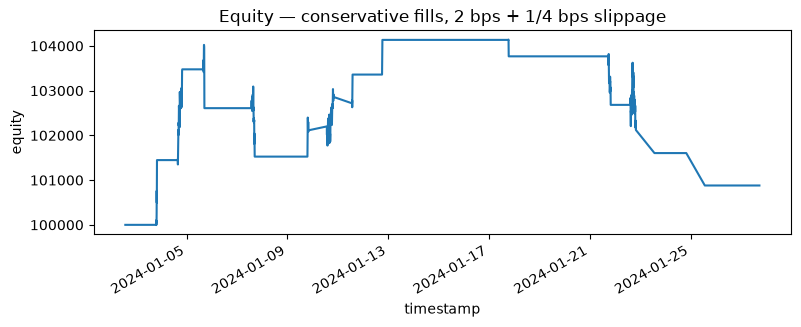

In [5]:
eq = result.equity
print(eq.tail(3)[["equity", "cash", "position", "price", "fees_paid"]])
ax = eq["equity"].plot(figsize=(9, 3), title="Equity — conservative fills, 2 bps + 1/4 bps slippage")
ax.set_ylabel("equity")

### 5.3 Reconciliation: prove the accounting

Every identity from section 3.3, checked in code. This is the test that catches the bugs you cannot see in a pretty chart.

In [6]:
final = result.equity.iloc[-1]
pos = result.portfolio.position   # flat: the engine liquidates at the end of the test

print(f"cash + position*price = {final['cash'] + pos.qty * final['price']:,.6f}")
print(f"equity                = {final['equity']:,.6f}")
assert abs(final["cash"] + pos.qty * final["price"] - final["equity"]) < 1e-6

realised = result.trades["net_pnl"].sum() if len(result.trades) else 0.0
unrealised = pos.qty * (final["price"] - pos.avg_price) if not pos.is_flat else 0.0
print(f"initial + realised + unrealised = {100_000 + realised + unrealised:,.6f}")
assert abs(100_000 + realised + unrealised - final["equity"]) < 1e-4

fees_from_fills = result.fills["fee"].sum() if len(result.fills) else 0.0
print(f"fees: fills={fees_from_fills:,.4f}  portfolio={final['fees_paid']:,.4f}")
assert abs(fees_from_fills - final["fees_paid"]) < 1e-6
print("\nAll accounting identities hold.")

cash + position*price = 100,879.792927
equity                = 100,879.792927
initial + realised + unrealised = 100,879.792927
fees: fills=113.6921  portfolio=113.6921

All accounting identities hold.


### 5.4 The anti-look-ahead audit

A strategy that peeks must crash, not profit. The engine turns the bug into an exception.

In [7]:
class Cheater(BaseStrategy):
    warmup = 1
    def generate(self, ctx):
        nxt = self.data.bar(ctx.bar.index + 1)     # tomorrow's close
        return {"side": "buy", "stop": nxt.close * 0.99, "target": nxt.close * 1.05, "reason": "cheat"}

try:
    BacktestEngine.build(df.head(200), Cheater(), initial_cash=100_000).run()
except LookAheadError as exc:
    print("Caught cheating as designed:")
    print("  ", exc)

Caught cheating as designed:
   Bar 2 is in the future (cursor=1). When handling bar t you may only read data with index <= t. If you need a completed pattern, wait for its confirmation bar.


### 5.5 Determinism

Run the same configuration twice and compare bit-for-bit. Any difference means hidden state, ordering or randomness.

In [8]:
def run_once():
    s = SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01))
    r = BacktestEngine.build(df, s, initial_cash=100_000).run()
    return r

a, b = run_once(), run_once()
np.testing.assert_allclose(a.equity["equity"].to_numpy(), b.equity["equity"].to_numpy())
print("identical equity over", len(a.equity), "bars")
print("identical trades    :", a.trades.equals(b.trades))
print("identical events    :", a.events.equals(b.events))

identical equity over 2000 bars
identical trades    : True
identical events    : True


### 5.6 Intrabar ambiguity: quantify the assumption

Same strategy, same data, same costs — only the tie-break changes. On wide brackets the difference is often zero because a single 5-min bar rarely contains both levels. **Measure that.** Then look at what happens when the bracket is tight relative to the bar range.

In [9]:
rows = []
for mode in ("conservative", "optimistic"):
    s = SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01))
    r = BacktestEngine.build(df, s, initial_cash=100_000,
                             model=ExecutionModel(fee_bps=2, slippage_bps=1, stop_slippage_bps=4),
                             ambiguity=mode).run()
    rows.append({"mode": mode, **{k: r.summary()[k] for k in ("trades", "total_return", "win_rate", "max_drawdown")}})
pd.DataFrame(rows).round(4)

,mode,trades,total_return,win_rate,max_drawdown
0,conservative,10,0.0088,0.4000,-0.0313
1,optimistic,10,0.0088,0.4000,-0.0313


Now the same experiment with a **tight bracket** on a high-volatility synthetic sample. Here both levels sit inside the same bar most of the time, so the assumption *is* the result.

In [10]:
class TightBracket(BaseStrategy):
    # Enter every 25 bars; stop and target only 0.5% away. A stress test for ambiguity.
    warmup = 20
    def generate(self, ctx):
        if ctx.is_flat and ctx.bar.index % 25 == 0:
            e = ctx.close
            return {"side": "buy", "stop": e * 0.995, "target": e * 1.005, "reason": "tight"}
        return None

stress = make_ohlcv(1200, freq="5min", seed=3, bar_vol_bps=120, session=None)
zero = ExecutionModel(fee_bps=0, slippage_bps=0, stop_slippage_bps=0, min_fee=0)
rows = []
for mode in ("conservative", "optimistic"):
    r = BacktestEngine.build(stress, TightBracket(sizer=FixedFractionSizer(risk_pct=0.01)),
                             initial_cash=100_000, model=zero, ambiguity=mode).run()
    s = r.summary()
    rows.append({"mode": mode, "trades": s["trades"], "return": s["total_return"],
                 "win_rate": s["win_rate"], "stops": int((r.trades["exit_reason"] == "stop").sum()),
                 "targets": int((r.trades["exit_reason"] == "take_profit").sum())})
pd.DataFrame(rows).round(4)

,mode,trades,return,win_rate,stops,targets
0,conservative,23,0.1554,0.1739,19,3
1,optimistic,23,0.3423,0.8261,4,18


A **+16% vs +34% result** and a **14% vs 82% win rate** — from an assumption, not
a market move. The lesson is not "use optimistic"; it is:

1. wide brackets on noisy data hide the problem (ties are rare),
2. tight brackets turn the problem into the whole result,
3. the fix is more information (1-min/ tick data, microbar paths) or fewer
   decisions per bar.

**Ambiguity exposure** is a number you can compute: the fraction of trades whose
holding bars contain both levels. If it is above a few percent, treat the backtest
as a range, not a point.

### 5.7 Batch vs streaming, and complexity

`engine.run()` is just `for i in range(n): engine.step(i)`. A streaming deployment replaces the range with a feed.

In [11]:
import time

# A streaming-style loop: one bar at a time, same components.
stream_engine = BacktestEngine.build(df.head(400), SweepBosFvgStrategy(
    SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01)), initial_cash=100_000)
stream_engine.strategy.on_start(stream_engine.data, stream_engine.logger)
for i in range(stream_engine.data.n_bars):
    stream_engine.step(i)
stream_result = stream_engine.result()
print("streamed bars:", len(stream_result.equity), "| final equity:", round(stream_result.equity['equity'].iloc[-1], 2))

# Linear scaling check (batch)
times = {}
for n in (500, 1000, 2000):
    sub = df.head(n)
    t0 = time.perf_counter()
    BacktestEngine.build(sub, SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer()),
                         initial_cash=100_000).run()
    times[n] = time.perf_counter() - t0
print({k: f"{v*1000:.0f} ms" for k, v in times.items()})
print("doubling bars roughly doubles time -> O(n) per bar, as designed")

streamed bars: 400 | final equity: 102871.48


{500: '100 ms', 1000: '241 ms', 2000: '725 ms'}
doubling bars roughly doubles time -> O(n) per bar, as designed


> **Coach's note.** If you profile the engine, most time will be in *your* `generate`, not in the loop. That is the right place for it: the plumbing should be boring and fast; the edge should be where you spend your thinking.

**How to expand this code**

- [ ] add a `Broker` adapter implementing `submit`/`process_bar` against a paper API;
- [ ] add multi-symbol `Portfolio` with exposure and correlation caps;
- [ ] add order amendments and cancels (replace, cancel-on-close);
- [ ] add a `PathSimulator` for intrabar resolution;
- [ ] add a walk-forward runner that owns train/test splits and the experiment log;
- [ ] add a run manifest (data hash, params, versions) written next to every result;
- [ ] add a CLI (`python -m intraday_engine.run --strategy ... --data ...`).

## 6. Unit tests

First, run the module's full suite (23 tests). Then look at the four engine-level
tests that matter most: determinism, look-ahead, order timing, and accounting.

In [12]:
import subprocess
res = subprocess.run([sys.executable, "-m", "pytest", "-q", str(BASE / "tests")],
                     capture_output=True, text=True, cwd=str(BASE))
print(res.stdout[-1500:])

.......................                                                  [100%]
23 passed in 0.74s



In [13]:
test_code = '''
import sys
from pathlib import Path
import numpy as np
import pytest

BASE = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "intraday_engine").is_dir())
sys.path.insert(0, str(BASE))
from intraday_engine import *

@pytest.fixture(scope="module")
def run():
    df = load_ohlcv_csv(str(BASE / "data" / "sample_5min_equity_1m.csv"))
    s = SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01))
    return BacktestEngine.build(df, s, initial_cash=100_000).run()

def test_equity_identity(run):
    last = run.equity.iloc[-1]
    assert last["equity"] == pytest.approx(last["cash"] + last["position"] * last["price"], abs=1e-6)

def test_every_fill_after_its_order(run):
    orders = run.events[run.events["kind"] == "ORDER"]
    if orders.empty:
        pytest.skip("no orders")
    for _, o in orders.iterrows():
        fill = run.events[(run.events["kind"] == "FILL") & (run.events["order_id"] == o["order_id"])]
        if not fill.empty:
            assert fill["bar_index"].min() > o["bar_index"]

def test_deterministic(run):
    s = SweepBosFvgStrategy(SweepBosFvgParams(), sizer=FixedFractionSizer(risk_pct=0.01))
    again = BacktestEngine.build(run.data.full_frame(), s, initial_cash=100_000).run()
    np.testing.assert_allclose(run.equity["equity"].to_numpy(), again.equity["equity"].to_numpy())

def test_no_future_reads_possible():
    df = load_ohlcv_csv(str(BASE / "data" / "pattern_sample.csv"))
    dh = DataHandler(df)
    dh.set_cursor(5)
    with pytest.raises(LookAheadError):
        dh.bar(6)
'''
path = Path(tempfile.mkdtemp()) / "test_lesson5.py"
path.write_text(test_code)
res = subprocess.run([sys.executable, "-m", "pytest", "-q", str(path)], capture_output=True, text=True)
print(res.stdout[-800:])

....                                                                     [100%]
4 passed in 1.59s



## 7. Example input and expected output

### A 12-bar run you can check with a pencil

Strategy: buy at the next open when `close > previous 3-bar high`, bracket with
stop 1% below the entry and target 2% above. Account \$10,000, risk 1%, no costs.

| Bar | Open | High | Low | Close | Event |
|---|---|---|---|---|---|
| 0–2 | 100 | 100.2 | 99.8 | 100 | flat |
| 3 | 100 | 100.5 | 99.9 | 100.4 | close > previous 3-bar high (100.2) → signal |
| 4 | 100.4 | 101.0 | 100.2 | 100.8 | entry fills at 100.4 |
| 5 | 100.8 | 101.2 | 99.0 | 99.5 | stop 99.4 touched → exit (conservative) |

Expected accounting: qty = `100 / (100.4 − 99.4) = 100`; loss = `100 × 1.0 = 100`
= exactly 1R. Equity \$9,900.

The cell builds exactly this case and prints the trade record.

In [14]:
idx = pd.date_range("2024-01-02 14:00", periods=6, freq="5min", tz="UTC")
pencil = pd.DataFrame(
    {"open": [100, 100, 100, 100, 100.4, 100.8],
     "high": [100.2, 100.2, 100.2, 100.5, 101.0, 101.2],
     "low":  [99.8, 99.8, 99.8, 99.9, 100.2, 99.0],
     "close": [100, 100, 100, 100.4, 100.8, 99.5],
     "volume": 1000},
    index=idx,
)

class PencilBreak(BaseStrategy):
    warmup = 3
    def generate(self, ctx):
        level = ctx.history["high"].iloc[-4:-1].max()
        if ctx.is_flat and ctx.close > level:
            stop = ctx.close * 0.99
            return {"side": "buy", "stop": stop, "target": stop + 2 * (ctx.close - stop),
                    "entry_ref": ctx.close, "reason": "3bar_break"}
        return None

zero = ExecutionModel(fee_bps=0, slippage_bps=0, stop_slippage_bps=0, min_fee=0)
pencil_res = BacktestEngine.build(pencil, PencilBreak(sizer=FixedFractionSizer(risk_pct=0.01)),
                                  initial_cash=10_000, model=zero).run()
print(pencil_res.fills[["bar_index", "side", "reason", "qty", "price"]].to_string(index=False))
print()
print(pencil_res.trades[["entry_price", "exit_price", "qty", "net_pnl", "exit_reason"]].to_string(index=False))
print()
print("equity:", pencil_res.equity["equity"].round(2).to_dict())

 bar_index side reason     qty    price
         4  buy market 99.6016 100.4000
         5 sell   stop 99.6016  99.3960

 entry_price  exit_price     qty   net_pnl exit_reason
    100.4000     99.3960 99.6016 -100.0000        stop

equity: {Timestamp('2024-01-02 14:00:00+0000', tz='UTC'): 10000.0, Timestamp('2024-01-02 14:05:00+0000', tz='UTC'): 10000.0, Timestamp('2024-01-02 14:10:00+0000', tz='UTC'): 10000.0, Timestamp('2024-01-02 14:15:00+0000', tz='UTC'): 10000.0, Timestamp('2024-01-02 14:20:00+0000', tz='UTC'): 10039.84, Timestamp('2024-01-02 14:25:00+0000', tz='UTC'): 9900.0}


**What to verify:** the entry is at bar 4's open (100.4), the stop is `100.4 × 0.99
= 99.396 ≈ 99.40`, the exit is at the stop (not at the low), and the loss is
≈ \$100 = 1% of equity. If any of those is off, the bug is in sizing, bracket
placement, or fill timing — in that order.

## 8. Exercises

### Exercise 5.1 — trailing bracket
Add a trailing stop to `ExecutionEngine` (or as a strategy `manage` rule). State
clearly which component owns it and why. Test that the stop never moves against
the position.

### Exercise 5.2 — multi-symbol portfolio
Extend `Portfolio` to a dict of positions and add a gross-exposure cap. Run two
correlated series and show how the cap changes drawdown. What breaks in the trade
record (one symbol per trade)?

### Exercise 5.3 — walk-forward
Split the sample into 3 folds. Fit one parameter (e.g. `expiry_bars`) on fold 1,
trade fold 2, roll. Compare with the best-in-sample parameter. How much of the
apparent edge survives?

### Exercise 5.4 — mutation test as a property
For 20 random `t`, copy the frame, multiply rows `> t` by 100, and assert the
signals produced up to `t` are unchanged. Wire it into `pytest` and make it fail
on purpose once, to be sure it can.

### Exercise 5.5 — microbar execution
Replace `_manage_brackets` with a path simulator seeded by bar index. Report the
distribution of total PnL over 100 seeds and compare with the conservative and
optimistic bounds. Where does the conservative assumption sit in that
distribution?

### Exercise 5.6 — streaming adapter
Write `StreamingEngine` that accepts one `Bar` at a time and reuses `Strategy`,
`ExecutionEngine` and `Portfolio`. Feed the same CSV bar by bar and assert the
final equity equals the batch run.

## 9. Common pitfalls and debugging

| Pitfall | Symptom | Fix |
|---|---|---|
| Growing history copied per bar | runtime explodes at ~50k bars | slice views / bounded windows; profile |
| `df.append` in a loop | O(n²) memory, slowdown | collect rows in a list, build once |
| Float cash drift | reconciliation off by cents after 100k fills | round cash to cents or accept 1e-6 tolerance |
| Open position at the end | trade stats ignore it | the engine flattens at the final close (`flatten_at_end=True`) |
| Annualising intraday Sharpe | absurd values (10+) | aggregate to daily returns first |
| In-sample parameter search | beautiful, fragile | walk-forward + few parameters |
| Logging every bar | huge files, slow runs | `log_bars=False`; log windows around trades |
| Using `datetime.now()` | non-reproducible | bar index only |
| Unseeded micro-path | different results per run | seed from bar index |
| Comparing strategies on different costs | wrong winner | one cost model, sensitivity table |

## 10. Recommended logging and diagnostics

### Run manifest (log once, at the start)

| Field | Why |
|---|---|
| data file + hash | know exactly what you tested |
| date range, bar count, timeframe | reproduce the sample |
| initial cash, currency | accounting context |
| execution model (fees, slippage, ambiguity) | results are meaningless without it |
| strategy name + parameters | experiment tracking |
| code version (`intraday_engine.__version__`) | reproducibility |
| RNG seed(s) | determinism |

### End-of-run report

```python
print(result.summary())
print(result.events["kind"].value_counts())
print(result.rejections()["message"].value_counts())
print(result.trades.groupby("exit_reason")["net_pnl"].agg(["count", "mean", "sum"]))
```

### Reconciliation block (always)

```python
last = result.equity.iloc[-1]
assert abs(last["cash"] + last["position"] * last["price"] - last["equity"]) < 1e-6
assert abs(result.fills["fee"].sum() - last["fees_paid"]) < 1e-6
```

### What "done" looks like

You have an engine you can trust when: the suite passes, the reconciliation holds,
a deliberate cheater crashes, two runs are identical, the conservative and
optimistic results are both reported, and the strategy survives 2–3× costs. Only
then is the next question interesting: *is there an edge?*

**Final notebook:** the capstone worksheet — write, test and stress *your own*
strategy with this engine.